In [ ]:
!pip install -q tensorflow scikit-learn pandas numpy matplotlib

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from google.colab import files
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

tf.keras.utils.set_random_seed(42)

uploaded = files.upload()
file_name = next(iter(uploaded))

df = pd.read_csv(file_name)
df.columns = df.columns.str.strip()

print("Dataset shape:", df.shape)
print(df.head())
print(df.info())

Saving DailyWeatherSynthetic.csv to DailyWeatherSynthetic.csv
Dataset shape: (1826, 5)
         date  meantemp  humidity  wind_speed  meanpressure
0  2018-01-01     15.91     77.19        3.00       1013.09
1  2018-01-02     12.91     83.04        2.93       1009.36
2  2018-01-03     16.82     68.05        2.87       1012.69
3  2018-01-04     17.21     71.13        2.71       1010.30
4  2018-01-05     10.83     80.90        2.34       1011.42
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1826 entries, 0 to 1825
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   date          1826 non-null   object 
 1   meantemp      1826 non-null   float64
 2   humidity      1826 non-null   float64
 3   wind_speed    1826 non-null   float64
 4   meanpressure  1826 non-null   float64
dtypes: float64(4), object(1)
memory usage: 71.5+ KB
None


Number of records: 1826
Date range: 2018-01-01 00:00:00 to 2022-12-31 00:00:00
Missing values:
 meantemp        0
humidity        0
wind_speed      0
meanpressure    0
dtype: int64
Gaps longer than one day: 0


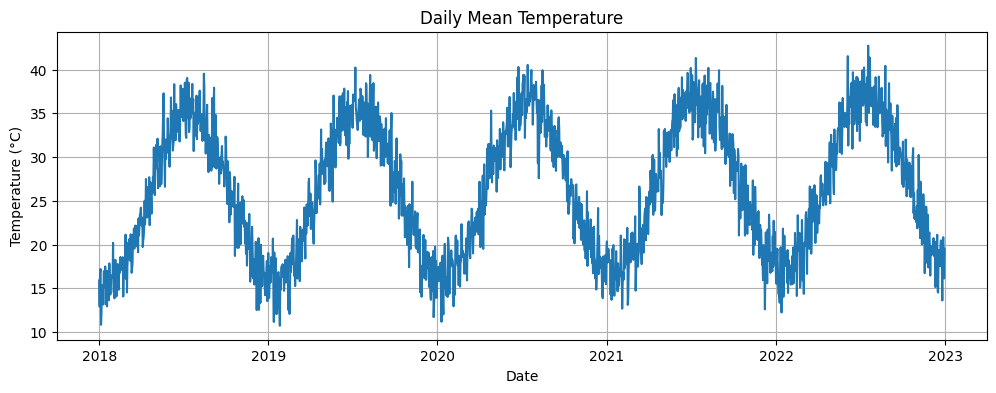

In [ ]:
# Convert date to datetime
df["date"] = pd.to_datetime(df["date"], errors="coerce")

# Convert weather measurements to numeric
features = ["meantemp", "humidity", "wind_speed", "meanpressure"]

for col in features:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Remove invalid dates and duplicate dates
df = df.dropna(subset=["date"])
df = df.sort_values("date")
df = df.drop_duplicates(subset=["date"], keep="first")

# Replace infinite values and handle missing measurements
df[features] = df[features].replace([np.inf, -np.inf], np.nan)
df[features] = df[features].interpolate(limit_direction="both")
df = df.dropna(subset=features).reset_index(drop=True)

# Verify daily continuity
date_gaps = df["date"].diff().dt.days
print("Number of records:", len(df))
print("Date range:", df["date"].min(), "to", df["date"].max())
print("Missing values:\n", df[features].isna().sum())
print("Gaps longer than one day:", (date_gaps > 1).sum())

if len(df) < 1000:
    raise ValueError("Dataset must contain at least 1000 valid records.")

if (date_gaps.dropna() != 1).any():
    raise ValueError(
        "There are gaps or irregular dates. Inspect and handle them "
        "before treating the observations as consecutive daily records."
    )

# View temperature over time
plt.figure(figsize=(12, 4))
plt.plot(df["date"], df["meantemp"])
plt.title("Daily Mean Temperature")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.grid(True)
plt.show()

In [ ]:
data = df[features].values.astype("float32")
dates = df["date"].values

n = len(df)

# Chronological split: 70% train, 15% validation, 15% test
train_end = int(n * 0.70)
val_end = int(n * 0.85)

# Fit scalers using training observations only
x_scaler = MinMaxScaler()
y_scaler = MinMaxScaler()

x_scaler.fit(data[:train_end])
y_scaler.fit(data[:train_end, [0]])

scaled_x = x_scaler.transform(data)
scaled_y = y_scaler.transform(data[:, [0]])

LOOKBACK = 30

def create_sequences(x, y, dates, lookback=30):
    X, Y, target_dates = [], [], []

    for i in range(lookback, len(x)):
        X.append(x[i-lookback:i])
        Y.append(y[i, 0])
        target_dates.append(dates[i])

    return (
        np.array(X, dtype="float32"),
        np.array(Y, dtype="float32"),
        np.array(target_dates)
    )

X, y, target_dates = create_sequences(
    scaled_x, scaled_y, dates, LOOKBACK
)

# Split by target date, preserving chronological order
target_dates_pd = pd.to_datetime(target_dates)
train_dates = pd.to_datetime(dates[train_end])
val_dates = pd.to_datetime(dates[val_end])

train_mask = target_dates_pd < train_dates
val_mask = (
    (target_dates_pd >= train_dates) &
    (target_dates_pd < val_dates)
)
test_mask = target_dates_pd >= val_dates

X_train, y_train = X[train_mask], y[train_mask]
X_val, y_val = X[val_mask], y[val_mask]
X_test, y_test = X[test_mask], y[test_mask]

dates_test = target_dates[test_mask]

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)

X_train: (1248, 30, 4)
X_val: (274, 30, 4)
X_test: (274, 30, 4)


In [ ]:
model = Sequential([
    tf.keras.Input(shape=(LOOKBACK, len(features))),
    LSTM(64, return_sequences=True),
    Dropout(0.2),
    LSTM(32),
    Dropout(0.2),
    Dense(16, activation="relu"),
    Dense(1)
])

model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=32,
    shuffle=False,
    callbacks=[early_stop],
    verbose=1
)

model.summary()

Epoch 1/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 6s 42ms/step - loss: 0.0791 - mae: 0.2271 - val_loss: 0.0106 - val_mae: 0.0830
Epoch 2/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - loss: 0.0171 - mae: 0.1034 - val_loss: 0.0076 - val_mae: 0.0695
Epoch 3/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 0.0147 - mae: 0.0963 - val_loss: 0.0072 - val_mae: 0.0681
Epoch 4/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - loss: 0.0153 - mae: 0.0974 - val_loss: 0.0070 - val_mae: 0.0682
Epoch 5/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - loss: 0.0131 - mae: 0.0902 - val_loss: 0.0071 - val_mae: 0.0684
Epoch 6/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - loss: 0.0113 - mae: 0.0851 - val_loss: 0.0069 - val_mae: 0.0678
Epoch 7/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - loss: 0.0117 - mae: 0.0846 - val_loss: 0.0073 - val_mae: 0.0695
Epoch 8/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - loss: 0.0124 - mae: 0.0878 - val_loss: 0.0074 - val_mae: 0.0697
Epoch 9/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - loss: 0.012

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_2 (LSTM)                   │ (None, 30, 64)         │        17,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 30, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 91,877 (358.90 KB)

 Trainable params: 30,625 (119.63 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 61,252 (239.27 KB)

In [ ]:
# Predict on unseen test observations
pred_scaled = model.predict(X_test, verbose=0)

y_actual = y_scaler.inverse_transform(
    y_test.reshape(-1, 1)
).flatten()

y_pred = y_scaler.inverse_transform(
    pred_scaled
).flatten()

mae = mean_absolute_error(y_actual, y_pred)
rmse = np.sqrt(mean_squared_error(y_actual, y_pred))

print(f"Test MAE:  {mae:.4f} °C")
print(f"Test RMSE: {rmse:.4f} °C")

Test MAE:  1.8780 °C
Test RMSE: 2.3240 °C


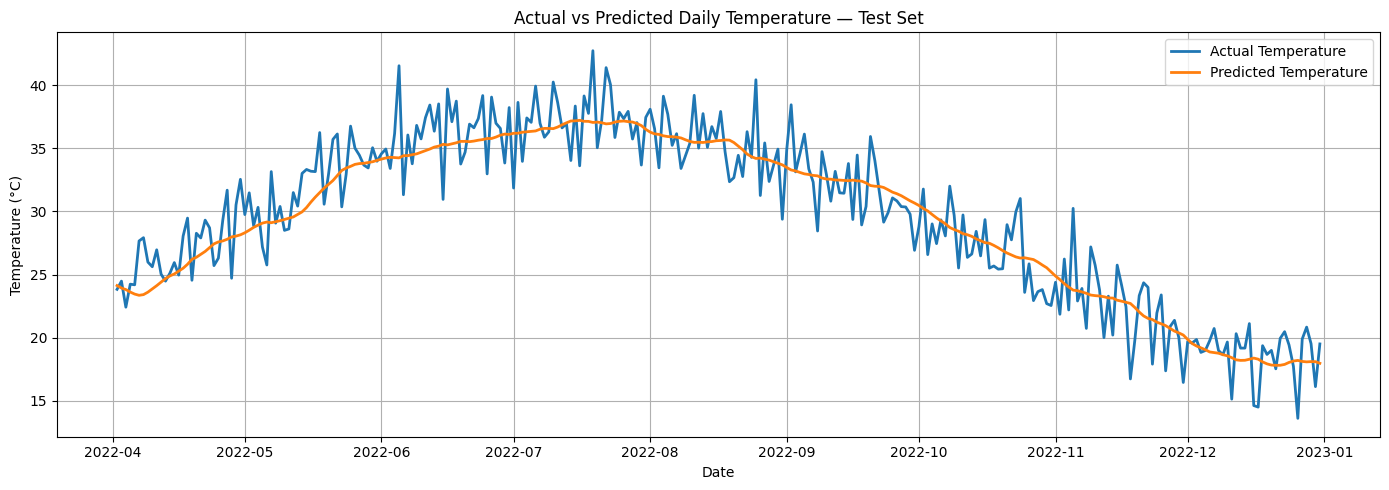

In [ ]:
plt.figure(figsize=(14, 5))

plt.plot(
    pd.to_datetime(dates_test),
    y_actual,
    label="Actual Temperature",
    linewidth=2
)

plt.plot(
    pd.to_datetime(dates_test),
    y_pred,
    label="Predicted Temperature",
    linewidth=2
)

plt.title("Actual vs Predicted Daily Temperature — Test Set")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()